<font color='steelblue' size=5><b>Комментарий ревьюера</b></font>

<font color='steelblue'>Привет, Мария! Меня зовут Михаил Костин, я буду проверять этот проект. Спасибо за проделанную работу! Предлагаю общаться на «ты». Но если это не удобно - дай знать, и мы перейдем на "вы".</font>

<font color='steelblue'>Я буду использовать различные цвета и знаки, чтобы было удобнее воспринимать мои комментарии:</font>


---


<font color='steelblue'>синий текст - просто текст комментария</font>

<font color='green'>✔️ и зеленый текст - все отлично</font>

<font color='darkorange'>⚠️ и оранжевый текст - сделано все правильно, однако есть рекомендации, на что стоит обратить внимание или что в следующий раз можно сделать по-другому. Ты можешь учесть эти комментарии при выполнении будущих заданий или доработать проект сейчас (однако это не обязательно).</font>

<font color='crimson'>❌ и красный текст - есть аспекты, с которыми принять проект в данной итерации не получится</font>

---

<font color='steelblue'>Давай работать над проектом в диалоге: если ты **что-то меняешь** в проекте по моим рекомендациям - **пиши об этом**. Выбери для своих комментариев какой-то заметный цвет, так мне будет легче отследить изменения.
Например, так: <b>Комментарий студента</b>

Пожалуйста, не удаляй мои комментарии в случае возврата работы, так будет проще разобраться, какие были недочеты, а также сразу увидеть исправленное. 

<b>Давай смотреть, что получилось!</b></font> 

# Выбор локации для скважины

Допустим, вы работаете в добывающей компании «ГлавРосГосНефть». Нужно решить, где бурить новую скважину.

Вам предоставлены пробы нефти в трёх регионах: в каждом 10 000 месторождений, где измерили качество нефти и объём её запасов. Постройте модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Проанализируйте возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

## Загрузка и подготовка данных

In [1]:
!pip install sweetviz

     |████████████████████████████████| 15.1 MB 2.4 MB/s eta 0:00:01


In [2]:
import pandas as pd
import sweetviz as sv
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from numpy.random import RandomState
from scipy import stats as st

<div class="alert alert-success">
<b>Комментарий ревьюера: ✔️ </b>

Хорошо, есть описание, импорты в одном месте.
</div> 

Скажите, пожалуйста
Как импортировать библиотеку sweetviz? Как здесь открыть терминал? Как установить ее вообще?

<div class="alert alert-success">
<b>Комментарий ревьюера: ✔️ </b>

Устанавливать библиотеки в самом ноутбуке можно с помощью `!pip install sweetviz` в кодовой ячейке
</div> 

Получим всю необходимую информацию о датасетах, где собрана информация по различным регионам

      id        f0        f1        f2     product
0  txEyH  0.705745 -0.497823  1.221170  105.280062
1  2acmU  1.334711 -0.340164  4.365080   73.037750
2  409Wp  1.022732  0.151990  1.419926   85.265647
3  iJLyR -0.032172  0.139033  2.978566  168.620776
4  Xdl7t  1.988431  0.155413  4.751769  154.036647
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


                                             |          | [  0%]   00:00 -> (? left)

AttributeError: module 'numpy' has no attribute 'exceptions'

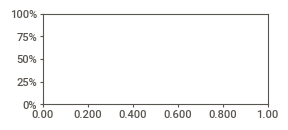

In [3]:
df0 = pd.read_csv('/datasets/geo_data_0.csv')
print(df0.head())
df0.info()
report0 = sv.analyze([df0, 'df0'])
report0.show_html('common_analysis_0.html')

      id         f0         f1        f2     product
0  kBEdx -15.001348  -8.276000 -0.005876    3.179103
1  62mP7  14.272088  -3.475083  0.999183   26.953261
2  vyE1P   6.263187  -5.948386  5.001160  134.766305
3  KcrkZ -13.081196 -11.506057  4.999415  137.945408
4  AHL4O  12.702195  -8.147433  5.004363  134.766305
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


                                             |          | [  0%]   00:00 -> (? left)

AttributeError: module 'numpy' has no attribute 'exceptions'

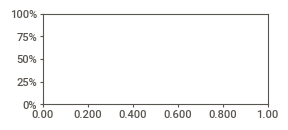

In [11]:
df1 = pd.read_csv('/datasets/geo_data_1.csv')
print(df1.head())
df1.info()
report1 = sv.analyze([df1, 'df1'])
report1.show_html('common_analysis_1.html')

      id        f0        f1        f2     product
0  fwXo0 -1.146987  0.963328 -0.828965   27.758673
1  WJtFt  0.262778  0.269839 -2.530187   56.069697
2  ovLUW  0.194587  0.289035 -5.586433   62.871910
3  q6cA6  2.236060 -0.553760  0.930038  114.572842
4  WPMUX -0.515993  1.716266  5.899011  149.600746
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


                                             |          | [  0%]   00:00 -> (? left)

AttributeError: module 'numpy' has no attribute 'exceptions'

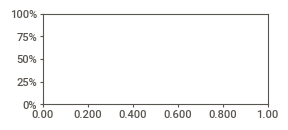

In [12]:
df2 = pd.read_csv('/datasets/geo_data_2.csv')
print(df2.head())
df2.info()
report2 = sv.analyze([df2, 'df2'])
report2.show_html('common_analysis_2.html')

<div class="alert alert-warning">
<b> Комментарий ревьюера ⚠️</b>

Хорошо, кроме info() можно посмотреть еще и на discribe(), визуализировать распределения.
    
Также хочу напомнить тебе, что по условиям задачи мы ограничены использованием только линейных моделей, а значит, может иметь место быть проблема [мультиколлинеарности](http://www.machinelearning.ru/wiki/index.php?title=Мультиколлинеарность). Хорошо бы было проверить это перед дальнейшими действиями.

## Обучение и проверка модели

Разделим данные на обучающую и валидационную выборки

In [4]:
features_df0 = df0.drop(['product', 'id'], axis=1)
target_df0 = df0['product']
features_train_df0, features_valid_df0, target_train_df0, target_valid_df0 = train_test_split(features_df0,
          target_df0, test_size=0.25, random_state=12345)

Создадим модель линейной регрессии для данного датасета, обучим ее и сделаем предсказания целевого признака

In [5]:
model_df0 = LinearRegression()
model_df0.fit(features_train_df0, target_train_df0)
predicted_valid_df0 = model_df0.predict(features_valid_df0)

Рассчитаем rmse

In [6]:
mse_df0 = mean_squared_error(target_valid_df0, predicted_valid_df0)
rmse_df0 = mse_df0 ** 0.5

Для того, чтобы определить, насколько хорош показатель rmse, рассчитаем его для "искусственных" предсказаний, которые будут являться обычным средним таргета обучающей выборки

In [7]:
predicted_valid_df0_mean = pd.Series(target_train_df0.mean(), index=target_valid_df0.index)
mse_df0_mean = mean_squared_error(target_valid_df0, predicted_valid_df0_mean)
rmse_df0_mean = mse_df0_mean ** 0.5

Это наблюдение объединяется в показателе R2, поэтому рассчитаем и его

In [8]:
r2_df0 = r2_score(target_valid_df0, predicted_valid_df0)
print('rmse for df0 is', rmse_df0)
print('"artificial" rmse fo df0 is', rmse_df0_mean)
print('r2 for df0 is', r2_df0)

rmse for df0 is 37.5794217150813
"artificial" rmse fo df0 is 44.289591053907365
r2 for df0 is 0.27994321524487786


<div class="alert alert-success">
<b>Комментарий ревьюера: ✔️ </b>

Круто, есть сравнение с "константной" моделью!
</div> 

Можно заметить, что предсказания модели существенно больше соответствуют таргету, чем среднее арифметическое обучающей выборки

Проделаем аналогичные действия с остальными датасетами

In [13]:
features_df1 = df1.drop(['product', 'id'], axis=1)
target_df1 = df1['product']
features_train_df1, features_valid_df1, target_train_df1, target_valid_df1 = train_test_split(features_df1,
                                                                                              target_df1, test_size=0.25, random_state=12345)
model_df1 = LinearRegression()
model_df1.fit(features_train_df1, target_train_df1)
predicted_valid_df1 = model_df1.predict(features_valid_df1)
mse_df1 = mean_squared_error(target_valid_df1, predicted_valid_df1)
rmse_df1 = mse_df1 ** 0.5
r2_df1 = r2_score(target_valid_df1, predicted_valid_df1)
print('rmse for df1 is', rmse_df1)
print('r2 for df1 is', r2_df1)

rmse for df1 is 0.893099286775617
r2 for df1 is 0.9996233978805127


Заметим, что предсказания для данного датасета отличаются исключительной точностью

In [14]:
features_df2 = df2.drop(['product', 'id'], axis=1)
target_df2 = df2['product']
features_train_df2, features_valid_df2, target_train_df2, target_valid_df2 = train_test_split(features_df2,
                                                                                              target_df2, test_size=0.25, random_state=12345)
model_df2 = LinearRegression()
model_df2.fit(features_train_df2, target_train_df2)
predicted_valid_df2 = model_df2.predict(features_valid_df2)
mse_df2 = mean_squared_error(target_valid_df2, predicted_valid_df2)
rmse_df2 = mse_df2 ** 0.5
r2_df2 = r2_score(target_valid_df2, predicted_valid_df2)
print('rmse for df2 is', rmse_df2)
print('r2 for df2 is', r2_df2)

rmse for df2 is 40.02970873393434
r2 for df2 is 0.20524758386040443


Поэксперементируем и создадим модель, которая будет обучаться на всех датасетах сразу, посмотрим, какими метрики будут у ее предсказаний

In [15]:
print('new common model')
df_common = pd.concat([df0, df1, df2])
print(df_common.head())
features_common = df_common.drop(['product', 'id'], axis=1)
target_common = df_common['product']
features_train_common, features_valid_common, target_train_common, target_valid_common = train_test_split(features_common,
                                                                                              target_common, test_size=0.25, random_state=12345)
model_common = LinearRegression()
model_common.fit(features_train_common, target_train_common)
predicted_common_df0 = model_common.predict(features_valid_df0)
mse_common_df0 = mean_squared_error(target_valid_df0, predicted_common_df0)
print('rmse of the common model for df0 is', mse_common_df0**0.5)


predicted_common_df1 = model_common.predict(features_valid_df1)
mse_common_df1 = mean_squared_error(target_valid_df1, predicted_common_df1)
print('rmse of the common model for df1 is',mse_common_df1**0.5)

predicted_common_df2 = model_common.predict(features_valid_df2)
mse_common_df2 = mean_squared_error(target_valid_df2, predicted_common_df2)
print('rmse of the common model for df2 is',mse_common_df2**0.5)

new common model
      id        f0        f1        f2     product
0  txEyH  0.705745 -0.497823  1.221170  105.280062
1  2acmU  1.334711 -0.340164  4.365080   73.037750
2  409Wp  1.022732  0.151990  1.419926   85.265647
3  iJLyR -0.032172  0.139033  2.978566  168.620776
4  Xdl7t  1.988431  0.155413  4.751769  154.036647
rmse of the common model for df0 is 39.63528714005472
rmse of the common model for df1 is 34.40884261761173
rmse of the common model for df2 is 41.737592306610956


Для датасетов df0 и df2 точность различается несущественно, однако rmse модели для датасета df1 намного хуже. Поэтому, плохая идея.

<div class="alert alert-success">
<b>Комментарий ревьюера: ✔️ </b>

Согласен, объединять такие статистически разные выборки (можно глянуть на распределения) не лучшая идея, отлично, что проверила это!
</div> 

## Подготовка к расчёту прибыли

рассчитаем сумму, которую должна приносить одна из двухста скважин для того, чтобы ее разработка не являлось убыточной

In [16]:
BUDGET = 10 ** 10
UNIT = 450000
NUMBER_IN_ONE_REGION = 200
BARRELS_IN_ONE_UNIT = 10 ** 3
THE_VOLUME_TO_AVOID_LOSS_IN_UNITS = BUDGET / NUMBER_IN_ONE_REGION / UNIT
print(THE_VOLUME_TO_AVOID_LOSS_IN_UNITS)
THE_VOLUME_TO_AVOID_LOSS_IN_BARRELS = THE_VOLUME_TO_AVOID_LOSS_IN_UNITS * BARRELS_IN_ONE_UNIT
print(THE_VOLUME_TO_AVOID_LOSS_IN_BARRELS)
THE_SUM_TO_AVOID_LOSS = THE_VOLUME_TO_AVOID_LOSS_IN_BARRELS * UNIT
print('the sum to avoid loss is', THE_SUM_TO_AVOID_LOSS)

111.11111111111111
111111.11111111111
the sum to avoid loss is 50000000000.0


<div class="alert alert-success">
<b>Комментарий ревьюера v2: ✔️ </b>

👍 
</div> 

In [17]:
print(df0['product'].mean() * UNIT)
print(df1['product'].mean() * UNIT)
print(df2['product'].mean() * UNIT)

41625000.00000001
30971250.000000007
42750000.00000002


Средние запасы во всех регионах существенно ниже, чем необходимое для безубыточной разработки количество сырья

<div class="alert alert-danger">
<b> Комментарий ревьюера ❌</b>

Используй в расчетах константы, которые ты задаешь ранее. Это важно, т.к. при смене даже одного показателя в работе придется искать глазами и переписывать весь код вручную, увеличивается шанс ошибки, в том числе и скрытой от глаз.
    
Также хочу обратить внимание на названия констант - по PEP-8 название констант записываются в верхнем регистре ([подробнее](https://peps.python.org/pep-0008/#constants)).
    
Для записи больших чисел, для более удобного чтения и чтобы не запутаться в нулях, можно использовать такую запись: 1_000_000 или возведение в степень числа 10.
    
Нет сравнения с средним запасом в каждом регионе
</div> 


<div class="alert alert-success">
<b>Комментарий ревьюера v2: ✔️ </b>

Все верно. Большинство скважин, судя по среднему, нам не подходит, поэтому мы и разрабатываем нашу модель — без нее наугад ничего не получится
</div> 

## Расчёт прибыли и рисков 

<div class="alert alert-danger">
<b> Комментарий ревьюера ❌</b>

Рано переходить к бутстрепу, выполни главу `4. Напишите функцию для расчёта прибыли по выбранным скважинам и предсказаниям модели` задания, функция, которые ты напишешь, понадобится в бутстрепе. 
    
Тут нужна функция, которая расчитает по поданным ей предсказаниям и реальным значениям прибыль из 200 лучших поданых скважин. Важно, что нам нужно узнать прибыль которую мы получим, а не ту, что мы предскажем. Для этого надо передать в функцию еще и таргеты и по индексам отсортированных предсказаний взять реальные значения и дальнейший расчет выполнять для них. (представим что мы предсказали для 500 точек, взяли из них в работу 200 лучших скважин и потом смотрим сколько мы из них в реальности достали нефти).
    
Не забудь учесть бюджет разработки, чтобы посчитать прибыль, а не выручку.
</div> 

Сделала новую функцию, которая считает выручку

In [ ]:
def real_profit(subsample, target):
    global BUDGET
    global UNIT
    global NUMBER_IN_ONE_REGION
    best_of_subsample = subsample.sort_values(ascending=False)[:NUMBER_IN_ONE_REGION]
    idx = list(best_of_subsample.index)
    target_chosen = target.loc[idx]
    vyruchka = target_chosen.sum() * UNIT
    profit = vyruchka - BUDGET
    return profit

Техникой Bootstrap создадим 1000 выборок, сохраним их средние в переменной, а также выбрем наиболее удачную выборку

<div class="alert alert-danger">
<b> Комментарий ревьюера ❌</b>

Интересная идея с нулевой гипотезой, но ты решаешь другую задачу :(

У нас сейчас все проще, мы должны взять 500 случайных точек 1000 раз, и для каждых 500 расчитать прибыль — как  раз той функцией из 4 Главы. Полученные прибыли мы сохраняем в список и далее работаем с ним — получаем доверительные интервалы прибыли в регионе и риск убытка (Убыток  — отрицательная прибыль). 
    
Аккуратнее с индексами предсказаний и реальных значений — после train_test_split и предсказания модели они могут быть разными и ты будешь сравнивать разные строки.
</div> 

<div class="alert alert-success">
<b>Комментарий ревьюера v2: ✔️ </b>

Хорошо, согласен с решением
   
</div> 

In [ ]:
state = RandomState(12345)
predicted_valid_df0 = pd.Series(predicted_valid_df0, index = features_valid_df0.index)
values_df0 = []
best_sample_df0 = predicted_valid_df0.sample(n=500, replace=True, random_state=state)
values_df0.append(best_sample_df0.mean())
for i in range(999):
    subsample = predicted_valid_df0.sample(n=500, replace=True, random_state=state)
    if subsample.mean() > best_sample_df0.mean():
        best_sample_df0 = subsample
    profit_from_subsample = real_profit(subsample, target_valid_df0)
    values_df0.append(profit_from_subsample)
print(real_profit(best_sample_df0, target_valid_df0), sum(values_df0) / len(values_df0))
values_df0 = pd.Series(values_df0)

<div class="alert alert-warning">
<b> Комментарий ревьюера v2 ⚠️</b>

Не понимаю зачем добавляешь `values_df0.append(best_sample_df0.mean())` в результирующий список прибылей отдельно до бутстрепа
   
</div> 

Из этих данных видно, что выборка действительно очень удачная

In [ ]:
interested_value = THE_SUM_TO_AVOID_LOSS
alpha = 0.05
confidence_interval_df0_real_profit = st.t.interval(alpha=0.95, df=len(values_df0)-1, 
                                        loc=values_df0.mean(), 
                                        scale=values_df0.sem())
print('Доверительный интервал для прибыли со всего региона 0 равен', confidence_interval_df0_real_profit)

Расчет доверительного интервала для средней выручки с региона 0

In [ ]:
print(len(values_df0[values_df0 < 0]) / NUMBER_IN_ONE_REGION)

<div class="alert alert-warning">
<b> Комментарий ревьюера v2 ⚠️</b>

Здесь и далее, делить надо на кол-во выбираемых точек (500), т.к. хотим получить значение риска при выборе 200 из 500.
</div> 

Расчет вероятности убытков. Большая цифра.

Теперь отберем 200 лучших скважин

In [ ]:
best_sample_df0_series = pd.Series(best_sample_df0)
best_sample_df0_series = best_sample_df0_series.drop_duplicates()
best_sample_df0_series_sorted = best_sample_df0_series.sort_values(ascending=False)
chosen_points_df0 = best_sample_df0_series_sorted[:NUMBER_IN_ONE_REGION]
df0_chosen = pd.concat([df0, chosen_points_df0], join='inner', axis=1)
df0_chosen = df0_chosen.rename(columns={0:'predictions'})
df0_chosen = df0_chosen.sort_values(by='predictions', ascending=False)
df0_chosen['expected_money'] = df0_chosen['predictions'] * UNIT
print(df0_chosen)
#получили все данные о 200 лучших точках региона df0
print(df0_chosen['product'].mean(), df0_chosen['predictions'].mean())
print('Рассчитаем прибыль и выручку')
profit_df0 = df0_chosen['predictions'].sum() * UNIT
print('the profit is', profit_df0)
print('the mean profit for the region df0 is', df0_chosen['predictions'].mean() * UNIT)
#посмотрим, что на самом деле
print('the actual profit is', df0_chosen['product'].mean() * UNIT)
print('Выручка равна', df0_chosen['predictions'].mean() * UNIT - BUDGET/NUMBER_IN_ONE_REGION)

Теперь рассчитаем 95% доверительный интервал для среднего арифметического этой выборки
H0 статистической гипотезы: среднее арифметическое прибыли с одной скважины равно пороговому значению

In [ ]:
lower_df0 = df0_chosen['expected_money'].quantile(0.025)
upper_df0 = df0_chosen['expected_money'].quantile(0.975)
confidence_interval_df0 = st.t.interval(alpha=0.95, df=len(df0_chosen['expected_money'])-1, loc=df0_chosen['expected_money'].mean(), scale=df0_chosen['expected_money'].sem())
print('the lower quantile is', lower_df0)
print('the upper quantile is', upper_df0)
print('the confidence interval for the chosen points of df0 is', confidence_interval_df0)
print('А еще рассчитаем вероятность того, что прибыль будет равна пороговому значению, значения меньше которого будут означать убытки')

results_df0 = st.ttest_1samp(df0_chosen['expected_money'], interested_value)
print('p-value', results_df0.pvalue)
if results_df0.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

Вероятность, мягко говоря, мала.

Аналогично и для других датасетов

In [ ]:
predicted_valid_df1 = pd.Series(predicted_valid_df1, index = features_valid_df1.index)
values_df1 = []
best_sample_df1 = predicted_valid_df1.sample(n=500, replace=True, random_state=state)
values_df1.append(best_sample_df1.mean())
for i in range(999):
    subsample = predicted_valid_df1.sample(n=500, replace=True, random_state=state)
    if subsample.mean() > best_sample_df1.mean():
        best_sample_df1 = subsample
    profit_from_subsample = real_profit(subsample, target_valid_df1)
    values_df1.append(profit_from_subsample)
print(real_profit(best_sample_df1, target_valid_df1), sum(values_df1) / len(values_df1))
values_df1 = pd.Series(values_df1)


best_sample_df1_series = pd.Series(best_sample_df1)
best_sample_df1_series = best_sample_df1_series.drop_duplicates()
best_sample_df1_series_sorted = best_sample_df1_series.sort_values(ascending=False)
chosen_points_df1 = best_sample_df1_series_sorted[:NUMBER_IN_ONE_REGION]
df1_chosen = pd.concat([df1, chosen_points_df1], join='inner', axis=1)
df1_chosen = df1_chosen.rename(columns={0:'predictions'})
df1_chosen = df1_chosen.sort_values(by='predictions', ascending=False)
df1_chosen['expected_money'] = df1_chosen['predictions'] * UNIT
print(df1_chosen)
#получили все данные о 200 лучших точках региона df1
print(df1_chosen['product'].mean(), df1_chosen['predictions'].mean())
profit_df1 = df1_chosen['predictions'].sum() * UNIT
print('the profit is', profit_df1)
print('the mean profit for the region df1 is', df1_chosen['predictions'].mean() * UNIT)
print('the actual profit is', df1_chosen['product'].mean() * UNIT)
print('Выручка равна', df1_chosen['predictions'].mean() * UNIT - BUDGET/NUMBER_IN_ONE_REGION)

lower_df1 = df1_chosen['expected_money'].quantile(0.025)
upper_df1 = df1_chosen['expected_money'].quantile(0.975)
confidence_interval_df1 = st.t.interval(alpha=0.95, df=len(df1_chosen['expected_money'])-1, loc=df1_chosen['expected_money'].mean(), scale=df1_chosen['expected_money'].sem())
print('the lower quantile is', lower_df1)
print('the upper quantile is', upper_df1)
print('the confidence interval for the chosen points of df1 is', confidence_interval_df1)
print('А еще рассчитаем вероятность того, что прибыль будет равна пороговому значению, значения меньше которого будут означать убытки')
results_df1 = st.ttest_1samp(df1_chosen['expected_money'], interested_value)
print('p-value', results_df1.pvalue)
if results_df1.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

In [ ]:
confidence_interval_df1_real_profit = st.t.interval(alpha=0.95, df=len(values_df1)-1, 
                                        loc=values_df1.mean(), 
                                        scale=values_df1.sem())
print('Доверительный интервал для прибыли со всего региона 1 равен', confidence_interval_df1_real_profit)

In [ ]:
print(len(values_df1[values_df1 < 0]) / NUMBER_IN_ONE_REGION)

В регионе 1 вероятность убытков довольно низкая.

In [ ]:
predicted_valid_df2 = pd.Series(predicted_valid_df2, index = features_valid_df2.index)
values_df2 = []
best_sample_df2 = predicted_valid_df2.sample(n=500, replace=True, random_state=state)
values_df2.append(best_sample_df2.mean())
for i in range(999):
    subsample = predicted_valid_df2.sample(n=500, replace=True, random_state=state)
    if subsample.mean() > best_sample_df2.mean():
        best_sample_df2 = subsample
    profit_from_subsample = real_profit(subsample, target_valid_df2)
    values_df2.append(profit_from_subsample)
print(real_profit(best_sample_df2, target_valid_df2), sum(values_df2) / len(values_df2))
values_df2 = pd.Series(values_df2)


best_sample_df2_series = pd.Series(best_sample_df2)
best_sample_df2_series = best_sample_df2_series.drop_duplicates()
best_sample_df2_series_sorted = best_sample_df2_series.sort_values(ascending=False)
chosen_points_df2 = best_sample_df2_series_sorted[:NUMBER_IN_ONE_REGION]
df2_chosen = pd.concat([df2, chosen_points_df2], join='inner', axis=1)
df2_chosen = df2_chosen.rename(columns={0:'predictions'})
df2_chosen = df2_chosen.sort_values(by='predictions', ascending=False)
df2_chosen['expected_money'] = df2_chosen['predictions'] * UNIT
print(df2_chosen)
#получили все данные о 200 лучших точках региона df2
print(df2_chosen['product'].mean(), df2_chosen['predictions'].mean())
profit_df2 = df2_chosen['predictions'].sum() * UNIT
print('the profit is', profit_df2)
print('the mean profit for the region df2 is', df2_chosen['predictions'].mean() * UNIT)
print('the actual profit is', df2_chosen['product'].mean() * UNIT)
print('Выручка равна', df2_chosen['predictions'].mean() * UNIT - BUDGET/NUMBER_IN_ONE_REGION)

lower_df2 = df2_chosen['expected_money'].quantile(0.025)
upper_df2 = df2_chosen['expected_money'].quantile(0.975)
confidence_interval_df2 = st.t.interval(alpha=0.95, df=len(df2_chosen['expected_money'])-1, loc=df2_chosen['expected_money'].mean(), scale=df2_chosen['expected_money'].sem())
print('the lower quantile is', lower_df2)
print('the upper quantile is', upper_df2)
print('the confidence interval for the chosen points of df2 is', confidence_interval_df2)
print('А еще рассчитаем вероятность того, что прибыль будет равна пороговому значению, значения меньше которого будут означать убытки')
results_df2 = st.ttest_1samp(df2_chosen['expected_money'], interested_value)
print('p-value', results_df2.pvalue)
if results_df2.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

In [ ]:
confidence_interval_df2_real_profit = st.t.interval(alpha=0.95, df=len(values_df2)-1, 
                                        loc=values_df2.mean(), 
                                        scale=values_df2.sem())
print('Доверительный интервал для прибыли со всего региона 2 равен', confidence_interval_df2_real_profit)

In [ ]:
print(len(values_df2[values_df2 < 0]) / NUMBER_IN_ONE_REGION)

Многовато.

In [ ]:
def getting_profit(predictions, indexation, df):
    predictions = pd.Series(predictions, index=indexation.index)
    best_sample = predictions.sample(n=500, replace=True, random_state=state)
    for i in range(999):
        subsample = predictions.sample(n=500, replace=True, random_state=state)
        if subsample.mean() > best_sample.mean():
            best_sample = subsample
    best_sample_series = pd.Series(best_sample)
    best_sample_series = best_sample_series.drop_duplicates()
    best_sample_series_sorted = best_sample_series.sort_values(ascending=False)
    chosen_points = best_sample_series_sorted[:NUMBER_IN_ONE_REGION]
    df_chosen = pd.concat([df, chosen_points], join='inner', axis=1)
    df_chosen = df_chosen.rename(columns={0: 'predictions'})
    df_chosen = df_chosen.sort_values(by='predictions', ascending=False)
    profit = df_chosen['predictions'].sum() * UNIT
    return profit

In [ ]:
print(getting_profit(predicted_valid_df0, features_valid_df0, df0))
print(getting_profit(predicted_valid_df1, features_valid_df1, df1))
print(getting_profit(predicted_valid_df2, features_valid_df2, df2))

ВЫВОДЫ

1) Предсказания модели довольно точны для решения данной задачи

2) Вероятность убытков для региона 0 и 2 очень существенна, для региона 1 - приемлима.

3) Средняя прибыль для регионов 0, 1, 2 соответственно находится в доверительных интервалах (379001719.133687, 412117322.5077313), (448481052.490845, 473194792.35434276), (375417279.25773364, 408996909.5804866). 

4) Для разработки скважин лучше всего подходит регион 1, так как прибыль в нем ожидается наибольшая, риск убытков наименьший, а в точности предсказаний модели можно не сомневаться.

<div class="alert alert-success">
<b>Комментарий ревьюера: ✔️ </b>

Отличный вывод, но придется пересмотреть по результатам внесения правок. 

## Чек-лист готовности проекта

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Выполнен шаг 1: данные подготовлены
- [ ]  Выполнен шаг 2: модели обучены и проверены
    - [ ]  Данные корректно разбиты на обучающую и валидационную выборки
    - [ ]  Модели обучены, предсказания сделаны
    - [ ]  Предсказания и правильные ответы на валидационной выборке сохранены
    - [ ]  На экране напечатаны результаты
    - [ ]  Сделаны выводы
- [ ]  Выполнен шаг 3: проведена подготовка к расчёту прибыли
    - [ ]  Для всех ключевых значений созданы константы Python
    - [ ]  Посчитано минимальное среднее количество продукта в месторождениях региона, достаточное для разработки
    - [ ]  По предыдущему пункту сделаны выводы
    - [ ]  Написана функция расчёта прибыли
- [ ]  Выполнен шаг 4: посчитаны риски и прибыль
    - [ ]  Проведена процедура *Bootstrap*
    - [ ]  Все параметры бутстрепа соответствуют условию
    - [ ]  Найдены все нужные величины
    - [ ]  Предложен регион для разработки месторождения
    - [ ]  Выбор региона обоснован

<div class="alert alert-info">
<b>Итоговый комментарий ревьюера</b> 
    
- Мария, в твоем проекте много хороших решений, код — достаточно лаконичный, ты делаешь достаточные комментарии в ходе работы, заканчиваешь основные главы выводами, все это помогает понять ход твоих мыслей и упрощает чтение проекта! Однако еще есть нюансы которые придется поправить (Минимум — Красные комментарии, а если хочешь прокачать проект — можно еще и часть желтых).
    
- Надеюсь, комментарии помогут закончить проект. Постараюсь повторно проверить твой проект как можно быстрее. Если у тебя появятся вопросы — задавай, я постараюсь ответить.

<div class="alert alert-info">
<b>Итоговый комментарий ревьюера v2</b> 
    
Извини за долгую проверку, были проблемы с платформой.
    
Твой проект готов :) Надеюсь, тебе понравился процесс выполнения и результат.

Ты проделала большую работу и правок оказалось совсем немного. Надеюсь мои комментарии помогут тебе в будущих проектах. Удачи!